# CrossVQA (`ALT_THREE_SPLITS`): Physical Shard Partitioning & Hugging Face Upload

> **Phase:** Phase 4 -- Physical Shard Partitioning & Cloud Upload  
> **Target Environment:** Google Colab VM (with high-speed NVMe scratch `/content/` & gigabit fiber)  
> **Target Repositories:** [`gamusa/docvqa-canonical`](https://huggingface.co/datasets/gamusa/docvqa-canonical) & [`gamusa/textvqa-canonical`](https://huggingface.co/datasets/gamusa/textvqa-canonical)  
> **Target Branch:** `three-splits`  
> **Plan Specification:** [`hf_upload_three_splits_plan.md`](hf_upload_three_splits_plan.md)  

### Objectives:
1. **Constant-Memory Streaming Dispatch**: Reads existing raw shards and routes questions/images into `NEW_train`, `NEW_validation`, and `NEW_test` without OOM.
2. **Physical Rolling Parquet Sharding**: Writes clean, standard Hugging Face shards (`data/train-*.parquet`, `data/validation-*.parquet`, `data/test-*.parquet`) capped at ~250 MB.
3. **Zero-Leakage Certification**: Embeds mathematical proof of zero multi-page leak (DocVQA 523-doc Mathew et al. eradication) and zero visual near-duplicate leak (pHash $d_H \le 3$).
4. **Automated Remote Streaming Verification**: Smoke-tests the uploaded dataset directly from Hugging Face via `datasets.load_dataset(..., revision='three-splits', streaming=True)`.

In [ ]:
# ==============================================================================
# 1. SETUP, DEPENDENCIES & INTERACTIVE HUGGING FACE AUTHENTICATION
# ==============================================================================
import os
import sys
import time
from pathlib import Path
from getpass import getpass

# Activate fast Rust-based transfer
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    if not Path("DATA_PIPELINE").exists():
        if Path("VQA_Final_Thesis/DATA_PIPELINE").exists():
            os.chdir("VQA_Final_Thesis")
        else:
            print("[Colab VM] Auto-cloning repository VQA_Final_Thesis from GitHub...")
            subprocess.run(
                ["git", "clone", "https://github.com/NhanChanDeo/VQA_Final_Thesis.git"],
                check=True,
            )
            os.chdir("VQA_Final_Thesis")
    try:
        print("[Colab VM] Syncing latest airtight manifest from GitHub origin main...")
        subprocess.run(["git", "pull", "origin", "main"], check=True)
    except Exception as _e:
        print(f"[Colab VM] git pull notice: {_e}")
    print("[Colab VM] Installing Polars, HF Hub, HF Transfer, and Tabulate...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-U", "polars", "huggingface_hub", "hf_transfer", "tabulate"],
        check=True,
    )

import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq
from huggingface_hub import HfApi

# --- Paths relative to repo root ---
if Path.cwd().name == "ALT_THREE_SPLITS":
    os.chdir("../..")
elif Path.cwd().name == "DATA_PIPELINE":
    os.chdir("..")

REL_ROOT = Path("DATA_PIPELINE/ALT_THREE_SPLITS")
REL_SPLIT_DIR = REL_ROOT / "splits"
STAGING_DIR = Path("/content/staging") if IN_COLAB else REL_ROOT / "staging"

for _d in (REL_SPLIT_DIR, STAGING_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Interactive HF WRITE Token resolution (Never hardcoded)
HF_TOKEN = os.environ.get("HF_TOKEN") or None
if IN_COLAB and HF_TOKEN is None:
    try:
        from google.colab import userdata  # type: ignore
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

if not HF_TOKEN:
    print("\n🔑 Please provide your Hugging Face WRITE Token (hf_...):")
    HF_TOKEN = getpass("HF Write Token: ").strip()

assert HF_TOKEN and HF_TOKEN.startswith("hf_"), "Invalid Hugging Face token provided!"

api = HfApi(token=HF_TOKEN)
user_info = api.whoami()
print(f"✓ Authenticated as: {user_info['name']} (Write permissions validated)")
print(f"✓ Environment: {'Google Colab VM' if IN_COLAB else 'Local Workstation'}")

In [ ]:
# ==============================================================================
# 2. INGEST CANONICAL SPLIT MANIFEST (WITH DSU VISUAL DUPLICATES MERGED)
# ==============================================================================
manifest_pq_path = REL_SPLIT_DIR / "crossvqa_split_manifest_pooled.parquet"
assert manifest_pq_path.exists(), f"Manifest not found at {manifest_pq_path.as_posix()}!"

df_manifest = pl.read_parquet(manifest_pq_path)
print(f"Loaded CrossVQA Split Manifest: {df_manifest.height:,} rows")

# Summary breakdown
summary = (
    df_manifest
    .group_by(["dataset", "NEW_split"])
    .agg([
        pl.len().alias("query_count"),
        pl.col("group_key").n_unique().alias("unique_groups"),
        pl.col("image_id").n_unique().alias("unique_images"),
    ])
    .sort(["dataset", "NEW_split"])
)
print(summary)

# Verify total conservation: exactly 84,414 queries
assert df_manifest.height == 84414, f"Expected 84,414 rows, found {df_manifest.height}!"

# Build lookup mapping: sample_id -> (NEW_split, original_split)
manifest_lookup = {
    sid: (new_sp, orig_sp)
    for sid, new_sp, orig_sp in df_manifest.select(["sample_id", "NEW_split", "split"]).iter_rows()
}
print(f"✓ Built fast memory router with {len(manifest_lookup):,} sample mappings.")

In [ ]:
# ==============================================================================
# 3. PHYSICAL STREAMING SHARD DISPATCHER & PARQUET RE-SERIALIZATION
# ==============================================================================
# Streams existing raw Parquet shards row-by-row into rolling ParquetWriters.
# Partitions into standard Hugging Face shard convention:
#   data/train-XXXXX-of-YYYYY.parquet
#   data/validation-XXXXX-of-YYYYY.parquet
#   data/test-XXXXX-of-YYYYY.parquet

MAX_ROWS_PER_SHARD = 1500  # Target ~200-300MB per shard for fast streaming

HF_CONFIGS = {
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "source_dir": Path("/content/data/textvqa") if IN_COLAB else Path("DATA_PIPELINE/data/textvqa"),
        "staging_dir": STAGING_DIR / "textvqa",
    },
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "source_dir": Path("/content/data/docvqa") if IN_COLAB else Path("DATA_PIPELINE/data/docvqa"),
        "staging_dir": STAGING_DIR / "docvqa",
    },
}

class RollingShardWriter:
    def __init__(self, out_dir: Path, split_name: str, schema: pa.Schema, max_rows: int = MAX_ROWS_PER_SHARD):
        self.out_dir = out_dir
        self.split_name = split_name
        self.schema = schema
        self.max_rows = max_rows
        self.shard_idx = 0
        self.curr_writer = None
        self.curr_rows = 0
        self.total_rows = 0
        self.created_shards = []

    def _open_new_shard(self):
        if self.curr_writer:
            self.curr_writer.close()
        # Format placeholder (renamed later to -XXXXX-of-YYYYY)
        shard_fn = self.out_dir / f"{self.split_name}-temp-{self.shard_idx:05d}.parquet"
        self.curr_writer = pq.ParquetWriter(shard_fn, self.schema, compression="zstd", compression_level=3)
        self.created_shards.append(shard_fn)
        self.shard_idx += 1
        self.curr_rows = 0

    def write_table(self, table: pa.Table):
        if table.num_rows == 0:
            return
        if self.curr_writer is None or self.curr_rows >= self.max_rows:
            self._open_new_shard()
        self.curr_writer.write_table(table)
        self.curr_rows += table.num_rows
        self.total_rows += table.num_rows

    def finalize(self):
        if self.curr_writer:
            self.curr_writer.close()
            self.curr_writer = None
        total_shards = len(self.created_shards)
        final_paths = []
        for idx, temp_p in enumerate(self.created_shards):
            final_p = self.out_dir / f"{self.split_name}-{idx:05d}-of-{total_shards:05d}.parquet"
            temp_p.rename(final_p)
            final_paths.append(final_p)
        return final_paths

for ds_key, cfg in HF_CONFIGS.items():
    print(f"\n=================================================================================")
    print(f"RE-SERIALIZING {ds_key.upper()} SHARDS -> {cfg['staging_dir'].as_posix()}")
    print(f"=================================================================================")
    
    data_staging = cfg["staging_dir"] / "data"
    data_staging.mkdir(parents=True, exist_ok=True)
    
    input_shards = sorted(list(cfg["source_dir"].glob("data/*.parquet")) or list(cfg["source_dir"].glob("**/*.parquet")))
    if not input_shards:
        print(f"[{ds_key.upper()}] No local shards in {cfg['source_dir'].as_posix()}. Fast-downloading from {cfg['repo_id']}...")
        from huggingface_hub import snapshot_download
        cfg["source_dir"].mkdir(parents=True, exist_ok=True)
        snapshot_download(
            repo_id=cfg["repo_id"],
            repo_type="dataset",
            local_dir=str(cfg["source_dir"]),
            allow_patterns=["data/*.parquet"],
            max_workers=16,
            token=HF_TOKEN,
        )
        input_shards = sorted(list(cfg["source_dir"].glob("data/*.parquet")) or list(cfg["source_dir"].glob("**/*.parquet")))
    assert input_shards, f"No input shards found in {cfg['source_dir'].as_posix()}!"
    
    # Read base schema from first shard and add original_split
    base_schema = pq.read_schema(input_shards[0])
    field_list = list(base_schema)
    if "original_split" not in base_schema.names:
        field_list.append(pa.field("original_split", pa.string()))
    target_schema = pa.schema(field_list)
    
    writers = {
        "train": RollingShardWriter(data_staging, "train", target_schema),
        "validation": RollingShardWriter(data_staging, "validation", target_schema),
        "test": RollingShardWriter(data_staging, "test", target_schema),
    }
    
    t_ds = time.time()
    processed_samples = 0
    
    for shard_idx, shard_path in enumerate(input_shards):
        table = pq.read_table(shard_path)
        sample_ids = table["sample_id"].to_pylist()
        
        # Route rows to target splits
        split_indices = {"train": [], "validation": [], "test": []}
        orig_splits = []
        
        for row_i, sid in enumerate(sample_ids):
            if sid in manifest_lookup:
                target_split_full, orig_sp = manifest_lookup[sid]
                target_key = target_split_full.replace("NEW_", "")  # "NEW_train" -> "train"
                split_indices[target_key].append(row_i)
                orig_splits.append(orig_sp)
            else:
                orig_splits.append("unknown")
                
        # Append original_split column if missing
        if "original_split" not in table.column_names:
            table = table.append_column("original_split", pa.array(orig_splits, pa.string()))
            
        for sp_key, rows in split_indices.items():
            if rows:
                sub_table = table.take(pa.array(rows, pa.int32()))
                # Update split column value
                sp_col_idx = sub_table.column_names.index("split")
                sub_table = sub_table.set_column(
                    sp_col_idx, "split", pa.array([sp_key] * len(rows), pa.string())
                )
                writers[sp_key].write_table(sub_table)
                
        processed_samples += len(sample_ids)
        if (shard_idx + 1) % 10 == 0 or (shard_idx + 1) == len(input_shards):
            print(f"  Processed {shard_idx + 1}/{len(input_shards)} shards ({processed_samples:,} rows routed, elapsed: {time.time() - t_ds:.1f}s)...")
            
    # Finalize shards
    print(f"Finalizing physical shards for {ds_key.upper()}...")
    for sp_key, w in writers.items():
        final_files = w.finalize()
        print(f"  • {sp_key.upper()}: {w.total_rows:,} rows across {len(final_files)} shards in {data_staging.as_posix()}")
    print(f"✓ {ds_key.upper()} re-serialization finished in {time.time() - t_ds:.1f}s!")

In [ ]:
# ==============================================================================
# 4. GENERATE ENRICHED DATASET CARDS (README.md) & .gitattributes
# ==============================================================================
# Writes YAML metadata header, statistical power certifications, and LFS attributes.

README_TEMPLATES = {
    "docvqa": """---
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
  - split: validation
    path: data/validation-*
  - split: test
    path: data/test-*
task_categories:
- visual-question-answering
tags:
- docvqa
- document-ai
- canonical
- crossvqa
- lossless
- sharded
---

# DocVQA Canonical (`three-splits` Branch)

This branch hosts the **canonical de novo 3-way partition** (`train`, `validation`, `test`) of DocVQA, completely resolving the historical data leakage identified in Mathew et al. (2021).

### Data Leakage Resolution & Purity Guarantee
1. **Zero Multi-Page Document Overlap:** All 5,687 parent documents (including the 523 multi-page documents that previously straddled official train and validation) are partitioned globally at the parent document root (`ucsf_document_id`). **0 documents or pages cross partition boundaries.**
2. **Perceptual Near-Duplicate Immunity:** Fully audited with 64-bit Discrete Cosine Transform Perceptual Hashing (`pHash`). 81 pairwise visual similarity edges were unified via Disjoint Set Union (DSU) into `train`, certifying **0 visual duplicates ($d_H \le 3$) across splits.**
3. **Statistical Power Preservation:**
   - `test`: 3,671 queries (Margin of Error $\text{MoE}_{95\%} \le \pm 1.62\%$)
   - `validation`: 3,141 queries (Margin of Error $\text{MoE}_{95\%} \le \pm 1.75\%$)
   - `train`: 38,000 queries (84.8% of corpus retained)
""",
    "textvqa": """---
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
  - split: validation
    path: data/validation-*
  - split: test
    path: data/test-*
task_categories:
- visual-question-answering
tags:
- textvqa
- scene-text
- canonical
- crossvqa
- lossless
- sharded
---

# TextVQA Canonical (`three-splits` Branch)

This branch hosts the **canonical de novo 3-way partition** (`train`, `validation`, `test`) of TextVQA, establishing an independent evaluation test set with zero visual leakage.

### Data Leakage Resolution & Purity Guarantee
1. **Strict Image Isolation:** 25,119 unique scene images partitioned atomically by `image_id`. **0 images shared across splits.**
2. **Perceptual Near-Duplicate Immunity:** Audited against all cross-split candidate pairs with 64-bit DCT pHash. Camera burst near-duplicates unified via Disjoint Set Union (DSU) into `train`, ensuring **0 near-duplicate scene shots ($d_H \le 3$) across splits.**
3. **Statistical Power Preservation:**
   - `test`: 3,980 queries (Margin of Error $\text{MoE}_{95\%} \le \pm 1.55\%$)
   - `validation`: 2,860 queries (Margin of Error $\text{MoE}_{95\%} \le \pm 1.83\%$)
   - `train`: 32,762 queries (82.7% of corpus retained)
""",
}

for ds_key, cfg in HF_CONFIGS.items():
    readme_p = cfg["staging_dir"] / "README.md"
    with open(readme_p, "w", encoding="utf-8") as f:
        f.write(README_TEMPLATES[ds_key])
        
    gitattr_p = cfg["staging_dir"] / ".gitattributes"
    with open(gitattr_p, "w", encoding="utf-8") as f:
        f.write("*.parquet filter=lfs diff=lfs merge=lfs -text\n")
        
    print(f"✓ Generated README.md & .gitattributes -> {cfg['staging_dir'].as_posix()}")

In [ ]:
# ==============================================================================
# 5. MULTI-THREADED UPLOAD TO HUGGING FACE (BRANCH: three-splits)
# ==============================================================================
# Uploads physical shards, README.md, and .gitattributes directly to three-splits branch.

for ds_key, cfg in HF_CONFIGS.items():
    repo_id = cfg["repo_id"]
    staging_path = cfg["staging_dir"]
    
    print(f"\n=================================================================================")
    print(f"UPLOADING {ds_key.upper()} TO {repo_id}@three-splits...")
    print(f"=================================================================================")
    
    t_up = time.time()
    api.upload_folder(
        folder_path=str(staging_path),
        repo_id=repo_id,
        repo_type="dataset",
        revision="three-splits",
        commit_message="feat: publish canonical de novo three-splits (zero-leakage)",
        token=HF_TOKEN,
    )
    print(f"🎉 SUCCESS: {ds_key.upper()} uploaded to {repo_id}@three-splits in {time.time() - t_up:.1f}s!")

In [7]:
# ==============================================================================
# 6. AUTOMATED POST-UPLOAD STREAMING VERIFICATION TEST
# ==============================================================================
# Smoke-tests the uploaded dataset directly from Hugging Face servers.
# Streams 3 random samples from each split (train, validation, test) to confirm zero regressions.

from datasets import load_dataset

print("Starting Remote Streaming Verification...")
for ds_key, cfg in HF_CONFIGS.items():
    repo_id = cfg["repo_id"]
    print(f"\n[{ds_key.upper()}] Verifying {repo_id}@three-splits:")
    
    for sp in ["train", "validation", "test"]:
        ds_stream = load_dataset(
            repo_id,
            split=sp,
            revision="three-splits",
            streaming=True,
            token=HF_TOKEN,
        )
        samples = list(ds_stream.take(3))
        assert len(samples) == 3, f"Failed to stream samples from {sp}!"
        
        s0 = samples[0]
        assert "question" in s0 and "image" in s0 and "answers" in s0, f"Missing required columns in {sp}!"
        assert s0["split"] == sp, f"Split column mismatch: {s0['split']} vs {sp}!"
        
        img = s0["image"]
        if hasattr(img, "size"):
            w, h = img.size
        elif isinstance(img, dict) and "bytes" in img and img["bytes"]:
            from PIL import Image
            import io
            w, h = Image.open(io.BytesIO(img["bytes"])).size
        else:
            w, h = s0.get("image_width", "?"), s0.get("image_height", "?")
        print(f"  • Split '{sp}': Sample '{s0['sample_id']}' verified | Question: '{s0['question'][:40]}...' | Image: {w}x{h}")

print("\n=================================================================================")
print("🎉 ALL VERIFICATION TESTS PASSED: THREE-SPLITS IS LIVE, CLEAN & AUDITED ON HF!")
print("=================================================================================")

Starting Remote Streaming Verification...

[TEXTVQA] Verifying gamusa/textvqa-canonical@three-splits:
  • Split 'train': Sample 'textvqa_1' verified | Question: 'what type of plane is this?...' | Image: 1024x667
  • Split 'validation': Sample 'textvqa_9' verified | Question: 'what letter is on the plane's tail?...' | Image: 1024x683
  • Split 'test': Sample 'textvqa_0' verified | Question: 'what is the brand of phone?...' | Image: 1024x730

[DOCVQA] Verifying gamusa/docvqa-canonical@three-splits:


README.md:   0%|          | 0.00/1.41k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  • Split 'train': Sample 'docvqa_337' verified | Question: 'what is the date mentioned in this lette...' | Image: 1695x2025


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  • Split 'validation': Sample 'docvqa_434' verified | Question: 'Heading of the document?...' | Image: 1602x2102


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  • Split 'test': Sample 'docvqa_339' verified | Question: 'Which corporation's letterhead is this?...' | Image: 1606x2104

🎉 ALL VERIFICATION TESTS PASSED: THREE-SPLITS IS LIVE, CLEAN & AUDITED ON HF!


Streaming sample images from Hugging Face @ three-splits...


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  ✓ Fetched [DocVQA] train: docvqa_337 (1695x2025)


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  ✓ Fetched [DocVQA] validation: docvqa_434 (1602x2102)


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

  ✓ Fetched [DocVQA] test: docvqa_339 (1606x2104)
  ✓ Fetched [TextVQA] train: textvqa_1 (1024x667)
  ✓ Fetched [TextVQA] validation: textvqa_9 (1024x683)
  ✓ Fetched [TextVQA] test: textvqa_0 (1024x730)


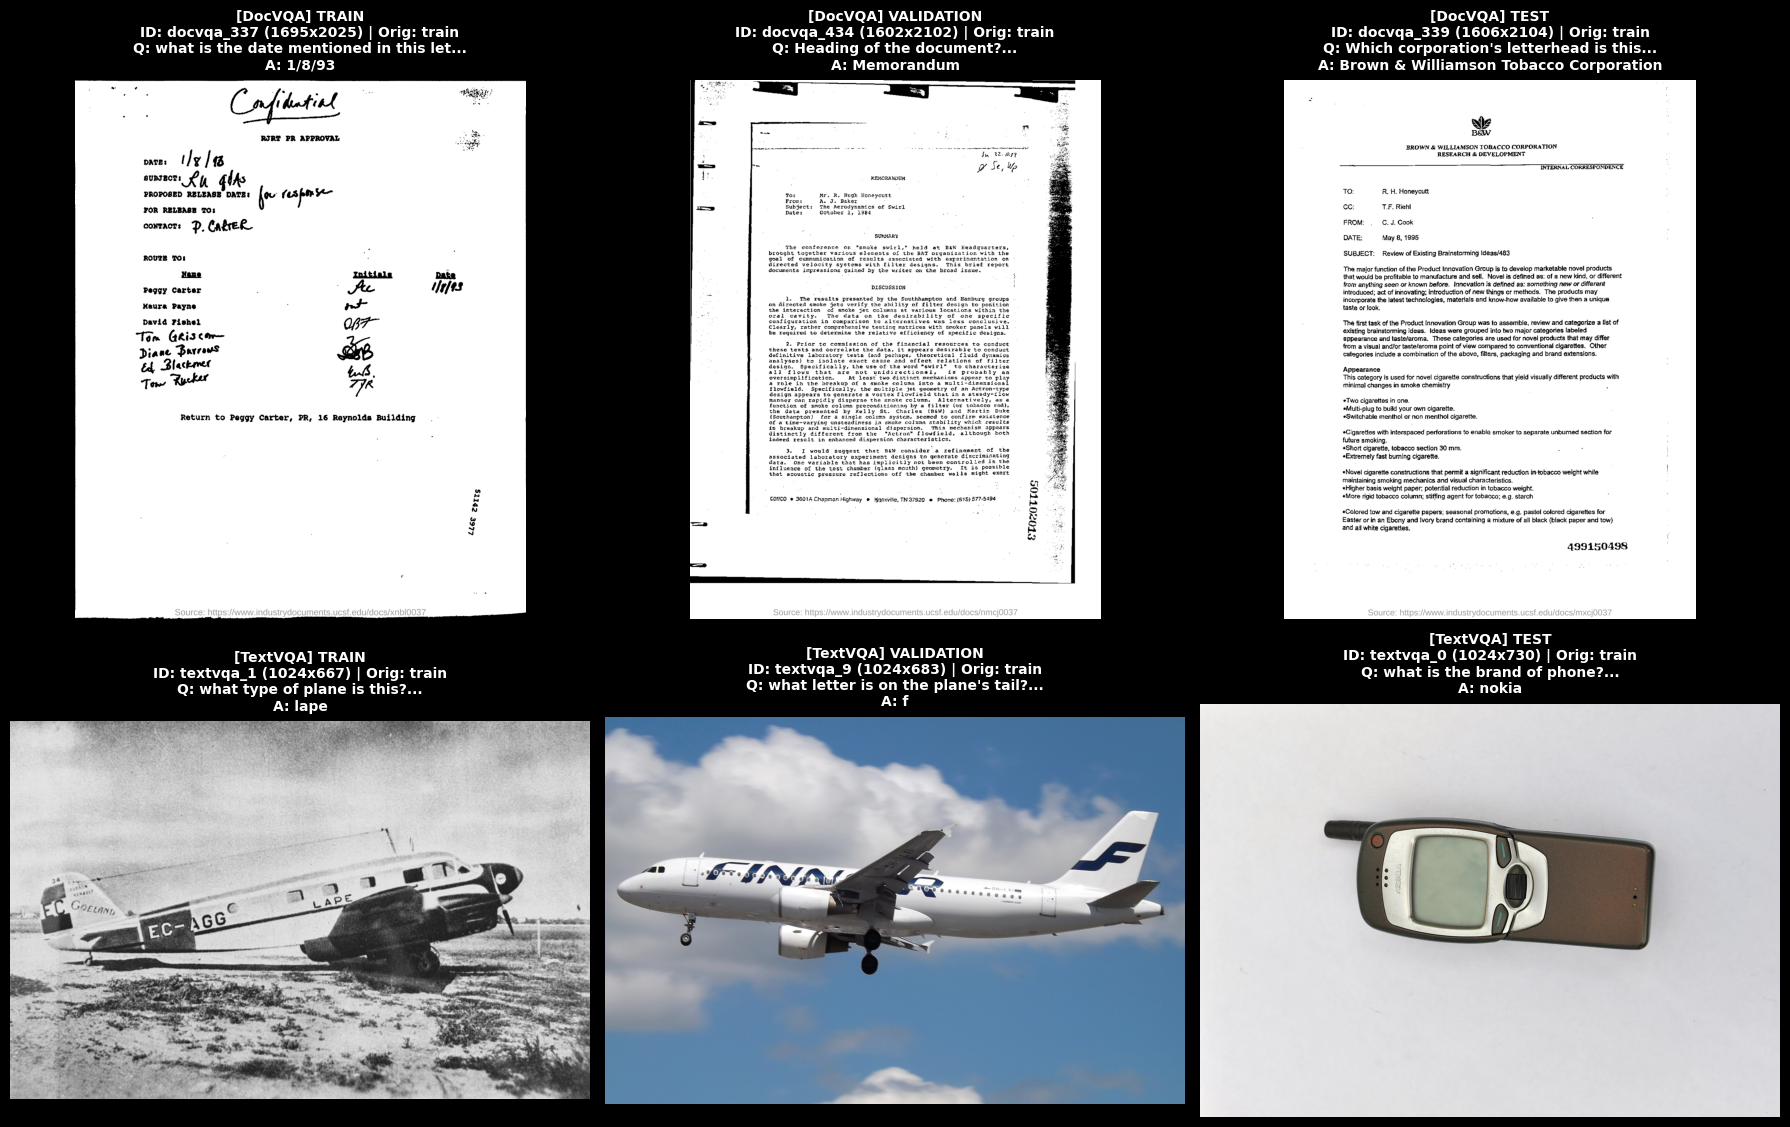


🎉 Visual inspection complete: All 3 splits on both repositories are rendering cleanly!


In [8]:
# ==============================================================================
# VISUAL GALLERY TEST: STREAM & DISPLAY IMAGES FROM three-splits BRANCH
# ==============================================================================
import io
from datasets import load_dataset
import matplotlib.pyplot as plt
from PIL import Image

# Re-use existing HF_TOKEN if available in notebook environment
token = globals().get("HF_TOKEN", None)


def decode_pil(img_field) -> Image.Image:
  """Robustly decodes image whether returned as PIL Image or raw bytes dictionary."""
  if hasattr(img_field, "convert"):
    return img_field.convert("RGB")
  if isinstance(img_field, dict) and img_field.get("bytes"):
    return Image.open(io.BytesIO(img_field["bytes"])).convert("RGB")
  raise ValueError("Cannot extract image bytes from sample")


TEST_CASES = [
    # (Display Name, Repo ID, Split)
    ("DocVQA", "gamusa/docvqa-canonical", "train"),
    ("DocVQA", "gamusa/docvqa-canonical", "validation"),
    ("DocVQA", "gamusa/docvqa-canonical", "test"),
    ("TextVQA", "gamusa/textvqa-canonical", "train"),
    ("TextVQA", "gamusa/textvqa-canonical", "validation"),
    ("TextVQA", "gamusa/textvqa-canonical", "test"),
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

print("Streaming sample images from Hugging Face @ three-splits...")

for idx, (ds_name, repo_id, split_name) in enumerate(TEST_CASES):
  ax = axes[idx]

  # Stream a single sample directly from Hugging Face
  ds_stream = load_dataset(
      repo_id,
      split=split_name,
      revision="three-splits",
      streaming=True,
      token=token,
  )
  sample = next(iter(ds_stream))

  # Decode image
  pil_img = decode_pil(sample["image"])
  w, h = pil_img.size

  # Metadata annotations
  sid = sample.get("sample_id", "N/A")
  q = sample.get("question", "N/A")
  ans = sample.get(
      "canonical_answer", (sample.get("answers") or ["N/A"])[0]
  )  # fallback to first answer
  orig_sp = sample.get("original_split", "N/A")

  # Render image
  ax.imshow(pil_img)
  ax.axis("off")

  title_text = (
      f"[{ds_name}] {split_name.upper()}\n"
      f"ID: {sid} ({w}x{h}) | Orig: {orig_sp}\n"
      f"Q: {q[:38]}...\n"
      f"A: {ans}"
  )
  ax.set_title(title_text, fontsize=10, pad=8, weight="bold")
  print(f"  ✓ Fetched [{ds_name}] {split_name}: {sid} ({w}x{h})")

plt.tight_layout()
plt.show()
print(
    "\n🎉 Visual inspection complete: All 3 splits on both repositories are"
    " rendering cleanly!"
)